# CNN 运行环境与 Animals-10 数据检查

本 Notebook 只负责验证 PyTorch/CUDA 环境、读取六类 Animals-10 元数据并预览图片。CNN 可复用代码位于 `src/cnn/`，完整训练与测试结果位于 `notebooks/03_cnn_training.ipynb`。

In [1]:
from pathlib import Path
import sys

# 同时兼容从项目根目录和 notebooks 目录启动 notebook。
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'src').exists() else cwd.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError(f'无法定位项目根目录，当前目录为 {cwd}')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('项目根目录:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])
print('解释器:', sys.executable)

项目根目录: D:\AI\animal-classification
Python: 3.14.8
解释器: D:\AI\animal-classification\.venv\Scripts\python.exe


In [2]:
import torch
import torchvision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('torchvision:', torchvision.__version__)
print('运行设备:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

# 实际执行一次 GPU/CPU 矩阵运算，避免只检查到驱动而没有进行计算。
x = torch.randn(512, 512, device=device)
y = x @ x.T
if device.type == 'cuda':
    torch.cuda.synchronize()
print('张量运算成功:', tuple(y.shape), y.device)

PyTorch: 2.14.1+cu130
torchvision: 0.29.1+cu130
运行设备: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
张量运算成功: (512, 512) cuda:0


## 检查 Animals-10 六类数据集

数据集只提供图片和类别标签。项目下载脚本从十类中选择猫、狗、鸡、马、牛、羊，并生成稳定的训练、验证、测试划分。这里不构造产生式规则所需的动物属性。

In [3]:
import pandas as pd
from src.labels import LABELS_ZH

DATA_ROOT = PROJECT_ROOT / 'data' / 'animals10'
metadata_path = DATA_ROOT / 'metadata.csv'
if not metadata_path.exists():
    raise FileNotFoundError(f'没有找到 {metadata_path}，请先运行 scripts/download_animals10.py')

metadata = pd.read_csv(metadata_path, encoding='utf-8-sig')
metadata['absolute_path'] = metadata['path'].map(lambda value: DATA_ROOT / value)
assert metadata['absolute_path'].map(Path.exists).all(), '清单中存在缺失图片'
assert set(metadata['label_zh']) == set(LABELS_ZH)

print('图片总数:', len(metadata))
pd.crosstab(metadata['label_zh'], metadata['split']).reindex(LABELS_ZH)

图片总数: 14774


split,test,train,val
label_zh,,,
猫,218,774,207
狗,735,3380,696
鸡,443,2110,440
马,404,1797,397
牛,256,1253,288
羊,209,968,199


C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 29483 (\N{CJK UNIFIED IDEOGRAPH-732B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 29399 (\N{CJK UNIFIED IDEOGRAPH-72D7}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 40481 (\N{CJK UNIFIED IDEOGRAPH-9E21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 39532 (\N{CJK UNIFIED IDEOGRAPH-9A6C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\sjcc\AppData\Local\Temp\ipykernel_14620\1349945872.py:12: UserWarning: Glyph 32650 (\N{CJK 

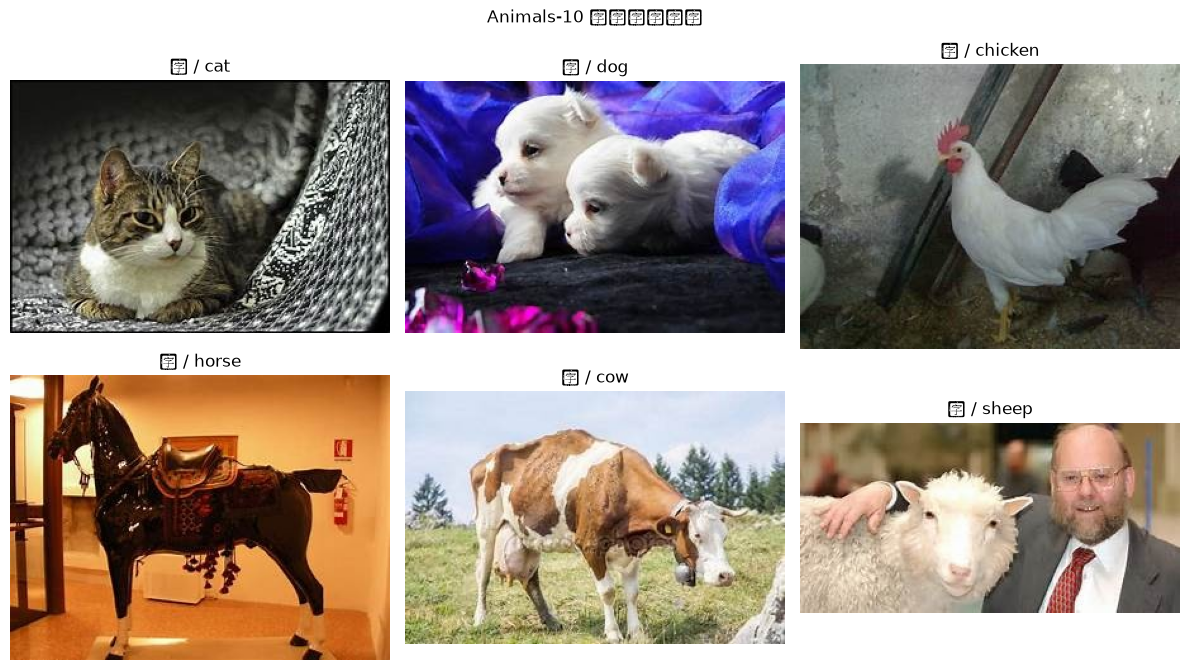

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for axis, animal in zip(axes.flat, LABELS_ZH):
    row = metadata[metadata['label_zh'] == animal].sample(1, random_state=42).iloc[0]
    with Image.open(row['absolute_path']) as image:
        axis.imshow(image.convert('RGB'))
    axis.set_title(f"{animal} / {row['label_en']}")
    axis.axis('off')
plt.suptitle('Animals-10 六类数据样例')
plt.tight_layout()
plt.show()

## 检查结论

以上检查已全部通过。ResNet18 迁移学习的数据加载、训练、验证和测试评价已经完成，具体实现与结果见 `src/cnn/` 和 `notebooks/03_cnn_training.ipynb`。